# Developed Markets Scorecard — **v3: disciplined signal search**
**US · Eurozone · UK · Switzerland · Japan** — cross-sectional (relative) outlook, 3–6 month horizon

## Why v3?
v1 and v2 did **not** produce a statistically reliable signal (v2 headline L/S Sharpe 0.18, permutation p = 0.24) and v2 was designed after looking at v1's results.
v3 widens the search to **all the supplied data** (2Y yields, credit spreads, FX, realised vol, richer PMI/FCI/EPS/price variants) — but a wider search needs *stronger* protection against false discoveries.

## Protocol (locked before any result was computed)
| Item | Choice |
|---|---|
| **Objective** | Find signals that rank the 5 markets by forward return better than chance, in a way that survives *selection bias* and *unseen data*. |
| **Library** | ~40 hypothesis-driven signals in 7 families. Each has a **direction fixed ex ante** from economic logic (below). No signal is added, dropped or sign-flipped after results. |
| **Target (primary)** | Cross-sectional Spearman rank-IC vs the **3M forward USD return** (implied price). Confirmations: local 3M, USD 6M, local 6M. |
| **Discovery window** | 2007-01 → 2016-12 (120 months). Signals ranked **only** on this window. |
| **Embargo** | 2017-01 → 2017-06 dropped (forward returns overlap → no leakage between windows). |
| **Validation window** | 2017-07 → latest. Signals are **frozen** before being looked at here. |
| **Selection-bias control** | Westfall-Young **max-statistic permutation test** on the discovery window: country labels shuffled in 3-month blocks (same shuffle for all signals → preserves their correlation); adjusted p = how often the *best of all N signals* under shuffling beats the observed signal. |
| **Signals tested on validation** | Top-5 by discovery z **plus** any with adjusted p ≤ 0.10. |
| **"Validated"** | validation IC > 0 **and** one-sided block-permutation p ≤ 0.05 (also shown ×k Bonferroni for k signals tested). |
| **Scorecard v3** | Built **only** from validated signals (equal weight within pillar, equal across pillars). No weight fitting. |
| **Excluded** | VIX and Brent are the *same series* for most markets (no cross-sectional information) → not usable in a relative scorecard. |

## Honest limits (read first)
* **Contaminated OOS for repeated families.** The v1/v2 families (EPS 3M, PMI 3M, FCI 3M, 12-1 momentum, P/E z) were already seen on the full 2010–2026 history; their "validation" is **not clean**. They are flagged `seen_before = True`. Families never examined before (yields, credit, FX, vol, extra lookbacks) have a **semi-clean** validation.
* Only 5 markets → low statistical power; a real IC of 0.05 is hard to distinguish from noise in ~100 months.
* If nothing validates, that is the answer — we do **not** relax the rule.

## Research ledger
| Exp | What | Outcome |
|---|---|---|
| 1 (v1) | 4 pillars, equal weights | no edge |
| 2 (v2) | FCI replaces PMI; walk-forward weights (4 specs examined) | modest, not significant |
| **3 (v3)** | **40-signal discovery / validation protocol (this notebook)** | see results |
| **3b (Stage 2)** | *Added after Stage-1 results were seen:* same 40 signals on the **full pooled sample** (max power) with the same max-statistic control | see results |

**Pillar-scorecard rule (fixed after Stage 2, before the composites were built):** the assignment needs multi-pillar scorecards, so two mechanical variants are built from the library —
**v3b (headline, "Tier-A")**: per pillar take the signal with the highest full-sample z *among signals that are positive in both windows*, and keep the pillar only if that signal also has full-sample unadjusted one-sided p ≤ 0.05; pillars without such a signal get **zero weight** (no evidence → no vote).
**v3c ("4 required pillars")**: Macro/Micro/Valuation/Technical each take their best both-window-positive signal (fallback: highest full-sample z if none), equal weights — the assignment-style scorecard.
v3a = EPS revision 6M alone (the Stage-1 validated signal). *v3b and v3c use pooled information (including the validation window) to pick signals, so their validation-window statistics are **not** clean out-of-sample.*

**Stage-2 rule (fixed before it was run):** a signal is *robust* if (i) its full-sample Westfall-Young adjusted p ≤ 0.10 **and** (ii) its IC is positive in **both** the discovery and the validation window. Stage 2 has multiplicity control but **no hold-out** (it uses all data), so it can never be called out-of-sample evidence.

## 0. Setup

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
import statsmodels.api as sm
from scipy.stats import rankdata, spearmanr
from IPython.display import display, Markdown

pd.options.display.float_format = '{:,.3f}'.format
pd.options.display.width = 220
pd.options.display.max_rows = 100
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})

ROOT = Path('..').resolve()
RAW, DATA = ROOT/'data'/'raw', ROOT/'data'
OUT = ROOT/'output'/'v3'; CH = OUT/'charts'
for p in (OUT, CH): p.mkdir(parents=True, exist_ok=True)

COUNTRIES = ['US', 'Eurozone', 'UK', 'Switzerland', 'Japan']
DISC = (pd.Period('2007-01', 'M'), pd.Period('2016-12', 'M'))
VAL_START = pd.Period('2017-07', 'M')
H_IC, P_PERM, SEED = 3, 3000, 7
ADJ_P_CAND, VAL_P, TOPK = 0.10, 0.05, 5

## 1. Data (same cleaning as v1/v2, plus 2Y yield and credit spread)

In [2]:
SPEC = {
 'US':          dict(file='US_raw_data.xlsx',  eps='Monthly_EPS', pmi='NAPMPMI Index',  fci=('GSFCI Index', -1),   y2='USGGT02Y Index', oas='LF98OAS Index',  fx=None),
 'Eurozone':    dict(file='EUR_raw_data.xlsx', eps='BEst EPS',    pmi='MPMIEZMA Index', fci=('BFCIEU Index', +1),  y2='GDBR2 Index',    oas='LECPOAS Index', fx=('EURUSD BGN Curncy', 'direct')),
 'UK':          dict(file='UK_raw_data.xlsx',  eps='BEst EPS',    pmi='MPMIGBMA Index', fci=('GSGBFCI Index', -1), y2='GUKG2 Index',    oas='LC61OAS Index', fx=('GBPUSD BGN Curncy', 'direct')),
 'Switzerland': dict(file='CH_raw_data.xlsx',  eps='BEst EPS',    pmi='CH_PMI',         fci=('GSEAFCI Index', -1), y2='GSWISS02 Index', oas='LECPOAS Index', fx=('USDCHF Curncy', 'invert')),
 'Japan':       dict(file='JPY_raw_data.xlsx', eps='BEst EPS',    pmi='JPYPMI',         fci=('GSJPFCI Index', -1), y2='GJGB2 Index',    oas='LJC1OAS Index', fx=('USDJPY BGN Curncy', 'invert')),
}
PE_COL = 'BEst P/E Ratio'

def load_country(s):
    d = pd.read_excel(RAW/s['file']).dropna(subset=['Date']).copy()
    d['month'] = pd.to_datetime(d['Date']).dt.to_period('M')
    d = d.sort_values('Date').drop_duplicates('month', keep='last').set_index('month')
    o = pd.DataFrame({'pe': d[PE_COL], 'eps': d[s['eps']], 'pmi': d[s['pmi']], 'y2': d[s['y2']], 'oas': d[s['oas']]})
    o['fci'] = s['fci'][1] * d[s['fci'][0]]                       # oriented: higher = EASIER conditions (sign verified vs VIX in v2)
    if s['fx'] is None: o['fx'] = 1.0
    else:
        col, how = s['fx']; o['fx'] = d[col] if how == 'direct' else 1.0 / d[col]
    return o

frames = {c: load_country(SPEC[c]) for c in COUNTRIES}
START = max(frames[c].pe.first_valid_index() for c in COUNTRIES); AS_OF = min(frames[c].index.max() for c in COUNTRIES)
IDX = pd.period_range(START, AS_OF, freq='M')
P = {k: pd.DataFrame({c: frames[c][k] for c in COUNTRIES}).reindex(IDX) for k in ('pe', 'eps', 'pmi', 'y2', 'oas', 'fci', 'fx')}
PE, EPS, PMI, Y2, OAS, FCI, FX = (P[k] for k in ('pe', 'eps', 'pmi', 'y2', 'oas', 'fci', 'fx'))
assert all(df.notna().all().all() for df in P.values()), 'missing values in common window'
print(f'Common window {START} -> {AS_OF} ({len(IDX)} months); no missing values in any of the 7 series.')

PX = PE * EPS; PX_USD = PX * FX
R_LOC, R_USD = PX.pct_change(), PX_USD.pct_change()
fwd = {('local', h): PX.shift(-h) / PX - 1 for h in (3, 6)}
fwd.update({('USD', h): PX_USD.shift(-h) / PX_USD - 1 for h in (3, 6)})
print('Why VIX/oil are excluded: identical series for US/UK/CH/JP (VIX) and all but Japan (Brent) -> zero cross-sectional variation.')

Common window 2005-12 -> 2026-04 (245 months); no missing values in any of the 7 series.
Why VIX/oil are excluded: identical series for US/UK/CH/JP (VIX) and all but Japan (Brent) -> zero cross-sectional variation.


## 2. Signal library — 40 hypotheses, direction fixed ex ante
Every signal is oriented so that **higher = expected better**. Changes in yields/spreads/FCI are scaled by their own expanding std (≥36 obs) so that markets with different units/volatility are comparable.

| Family | Direction rationale (committed before testing) |
|---|---|
| Micro (EPS) | rising/accelerating forward EPS → upgrades continue; EPS growth ahead of price → cheapening |
| Valuation | cheap vs own history / vs peers / vs bonds (equity risk premium) → higher returns |
| Rates | falling 2Y yield (easier policy expectations) → good; high yield vs own history → bad |
| Credit | tightening spreads → good (risk-on); *wide* spread vs own history → good (compensation) |
| FX | currency appreciation momentum → higher USD return (trend persistence) |
| Technical | momentum (3–12M), trend, proximity to high → good; 1M reversal and high realised vol → bad |
| Macro | PMI improving / high, FCI easing → good |

In [3]:
def chg(x, L): return x - x.shift(L)
def pct(x, L): return x / x.shift(L) - 1
def zexp(x, m=36): return (x - x.expanding(m).mean()) / x.expanding(m).std()
def own(d, m=36): return d / d.expanding(m).std()
def mom(a, b): return PX.shift(a) / PX.shift(b) - 1

LIB, META = {}, {}
def add(name, pillar, df, seen=False):
    LIB[name] = df.reindex(IDX); META[name] = {'pillar': pillar, 'seen_before': seen}

# micro
for L, seen in ((1, False), (3, True), (6, False), (12, False)): add(f'EPS revision {L}M', 'Micro', pct(EPS, L), seen)
add('EPS acceleration (3M vs prior 3M)', 'Micro', pct(EPS, 3) - pct(EPS, 3).shift(3))
add('EPS growth minus price growth 6M', 'Micro', pct(EPS, 6) - pct(PX, 6))
# valuation
add('P/E z-score (own history, inverted)', 'Valuation', -zexp(PE), True)
add('Equity risk premium z (E/P − 2Y yield)', 'Valuation', zexp(100 / PE - Y2))
add('Relative P/E vs peers, z (inverted)', 'Valuation', -zexp(PE.div(PE.mean(axis=1), axis=0)))
# rates
for L in (1, 3, 6, 12): add(f'2Y yield change {L}M (falling = good)', 'Rates', -own(chg(Y2, L)))
add('2Y yield level z (high = bad)', 'Rates', -zexp(Y2))
# credit
for L in (1, 3, 6): add(f'Credit spread change {L}M (tightening = good)', 'Credit', -own(chg(OAS, L)))
add('Credit spread level z (wide = good)', 'Credit', zexp(OAS))
# fx
for L in (3, 6, 12): add(f'FX appreciation momentum {L}M', 'FX', pct(FX, L))
# technical
add('Reversal 1M (inverted)', 'Technical', -pct(PX, 1))
for a, b, nm, seen in ((1, 4, 'Momentum 3-1M', False), (1, 7, 'Momentum 6-1M', False), (1, 10, 'Momentum 9-1M', False), (1, 12, 'Momentum 12-1M', True)): add(nm, 'Technical', mom(a, b), seen)
add('Risk-adjusted momentum 12-1M', 'Technical', mom(1, 12) / R_LOC.rolling(12).std())
add('Price vs 10M moving average', 'Technical', PX / PX.rolling(10).mean() - 1)
add('Distance to 12M high', 'Technical', PX / PX.rolling(12).max() - 1)
add('Low realised vol (12M, inverted)', 'Technical', -R_LOC.rolling(12).std())
# macro
PM = PMI.shift(1)                                                  # PMI published ~1st business day of next month -> 1M lag
for L, seen in ((1, False), (3, True), (6, False)): add(f'PMI change {L}M (lag 1M)', 'Macro', chg(PM, L), seen)
add('PMI level (lag 1M)', 'Macro', PM)
add('PMI vs own 12M average (lag 1M)', 'Macro', PM - PM.rolling(12).mean())
for L, seen in ((1, False), (3, True), (6, False), (12, False)): add(f'FCI easing {L}M', 'Macro', own(chg(FCI, L)), seen)
add('FCI level z (easing)', 'Macro', zexp(FCI))

NAMES = list(LIB); N = len(NAMES)
lib_tab = pd.DataFrame(META).T.assign(n=1).groupby('pillar').n.sum().to_frame('# signals')
print(f'Library size N = {N}'); display(lib_tab.T)

Library size N = 40


pillar,Credit,FX,Macro,Micro,Rates,Technical,Valuation
# signals,4,3,10,6,5,9,3


## 3. Vectorised cross-sectional IC engine
For every signal and month: Spearman correlation across the 5 markets between the signal and the forward return (average ranks handle ties). Newey-West t-stats use lags = 3 (overlapping 3M returns).

In [4]:
def rank_array(df):
    a = df.to_numpy(float); out = np.full(a.shape, np.nan); ok = ~np.isnan(a).any(1)
    out[ok] = rankdata(a[ok], axis=1); return out

S = np.stack([rank_array(LIB[n]) for n in NAMES])                  # (N, T, 5)
FR = {k: rank_array(v) for k, v in fwd.items()}                    # (T, 5)

def ic_matrix(S, Fr):
    Sv, Fv = np.nan_to_num(S - 3.0), np.nan_to_num(Fr - 3.0)
    num = np.einsum('ntc,tc->nt', Sv, Fv); den = np.sqrt((Sv**2).sum(2) * (Fv**2).sum(1)[None, :])
    with np.errstate(all='ignore'): ic = num / den
    bad = (den == 0) | np.isnan(S[:, :, 0]) | np.isnan(Fr[:, 0])[None, :]
    ic[bad] = np.nan; return ic

def nw_t(x, lags=H_IC):
    x = x[~np.isnan(x)]
    return float(sm.OLS(x, np.ones(len(x))).fit(cov_type='HAC', cov_kwds={'maxlags': lags}).tvalues[0]) if len(x) > 12 else np.nan

M_DISC = np.array([DISC[0] <= p <= DISC[1] for p in IDX]); M_VAL = np.array([p >= VAL_START for p in IDX])
IC = {k: ic_matrix(S, FR[k]) for k in FR}
def window_stats(ic, mask):
    sub = ic[:, mask]
    return np.nanmean(sub, axis=1), np.array([nw_t(r) for r in sub]), (~np.isnan(sub)).sum(1)

## 4. Discovery (2007-01 → 2016-12) with Westfall-Young max-statistic control
*Question:* if all 40 signals were noise, how good would the **best** one look? Adjusted p = probability that the best-of-N noise signal beats the observed one.

,pillar,seen_before,disc_months,disc_IC,disc_NW_t,disc_z,disc_p_raw,disc_p_adj(WY)
"Relative P/E vs peers, z (inverted)",Valuation,False,98,+0.174,+2.31,+2.64,0.005,0.117
"P/E z-score (own history, inverted)",Valuation,True,98,+0.167,+2.97,+2.56,0.006,0.145
Equity risk premium z (E/P − 2Y yield),Valuation,False,98,+0.144,+2.13,+2.09,0.020,0.401
EPS revision 6M,Micro,False,120,+0.117,+1.67,+1.95,0.025,0.515
EPS revision 12M,Micro,False,120,+0.122,+1.61,+1.95,0.026,0.516
2Y yield change 6M (falling = good),Rates,False,92,+0.123,+1.74,+1.82,0.038,0.616
Credit spread level z (wide = good),Credit,False,98,+0.111,+1.28,+1.74,0.044,0.679
2Y yield level z (high = bad),Rates,False,98,+0.114,+1.62,+1.67,0.043,0.736
EPS growth minus price growth 6M,Micro,False,120,+0.080,+1.35,+1.43,0.079,0.883
Credit spread change 1M (tightening = good),Credit,False,97,+0.070,+1.31,+1.32,0.095,0.924


Signals with WY-adjusted p <= 0.1: 0   |   unadjusted p <= 0.05: 8  (expected by chance alone ≈ 2)
Best observed z = 2.64; best-of-40 NULL z: median 1.96, 95th pct 2.95
Wrong-sign check: signals with strongly NEGATIVE discovery IC (raw p >= 0.95): 1


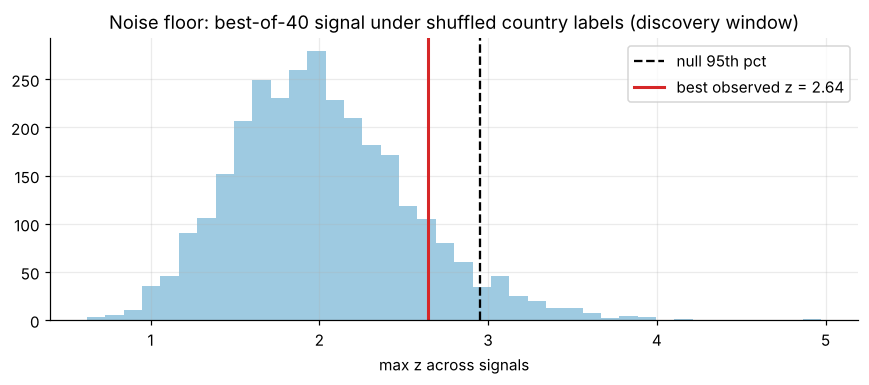

In [5]:
def block_perm_null(S, Fr, mask, h=H_IC, P=P_PERM, seed=SEED):
    Sd, Fd = S[:, mask, :], Fr[mask, :]
    valid = ~np.isnan(Sd[:, :, 0]) & ~np.isnan(Fd[:, 0])[None, :]
    Sc, Fc = np.nan_to_num(Sd - 3.0), np.nan_to_num(Fd - 3.0)
    den = np.sqrt((Sc**2).sum(2) * (Fc**2).sum(1)[None, :])
    valid = valid & (den > 0); den[den == 0] = 1                      # all-tied months (e.g. every market at its 12M high) carry no information
    nv = np.maximum(valid.sum(1), 1)
    obs = (np.einsum('ntc,tc->nt', Sc, Fc) / den * valid).sum(1) / nv
    T_ = Sd.shape[1]; blk = np.arange(T_) // h; B = blk.max() + 1
    perms = np.argsort(np.random.default_rng(seed).random((P, B, 5)), axis=2)
    Mn = np.empty((P, Sd.shape[0]))
    for p in range(P):                                                # same shuffle for all signals -> correlation preserved
        Sp = np.take_along_axis(Sc, perms[p][blk][None], axis=2)
        Mn[p] = (np.einsum('ntc,tc->nt', Sp, Fc) / den * valid).sum(1) / nv
    mu, sd = Mn.mean(0), Mn.std(0); zobs = (obs - mu) / sd; zn = (Mn - mu) / sd
    p_raw = np.array([(1 + (zn[:, i] >= zobs[i]).sum()) / (P + 1) for i in range(len(obs))])
    mx = zn.max(1); p_adj = np.array([(1 + (mx >= zobs[i]).sum()) / (P + 1) for i in range(len(obs))])
    return obs, zobs, p_raw, p_adj, mx

key = ('USD', 3)
ic_d, t_d, n_d = window_stats(IC[key], M_DISC)
obs_d, z_d, praw_d, padj_d, maxnull_d = block_perm_null(S, FR[key], M_DISC)
assert np.allclose(obs_d, ic_d, atol=1e-9)                        # permutation engine reproduces the plain mean IC
disc = pd.DataFrame({'pillar': [META[n]['pillar'] for n in NAMES], 'seen_before': [META[n]['seen_before'] for n in NAMES],
                     'disc_months': n_d, 'disc_IC': ic_d, 'disc_NW_t': t_d, 'disc_z': z_d, 'disc_p_raw': praw_d, 'disc_p_adj(WY)': padj_d}, index=NAMES)
disc = disc.sort_values('disc_z', ascending=False)
display(disc.head(15).style.format({'disc_IC': '{:+.3f}', 'disc_NW_t': '{:+.2f}', 'disc_z': '{:+.2f}', 'disc_p_raw': '{:.3f}', 'disc_p_adj(WY)': '{:.3f}'}))
print(f'Signals with WY-adjusted p <= {ADJ_P_CAND}: {(disc["disc_p_adj(WY)"] <= ADJ_P_CAND).sum()}   |   unadjusted p <= 0.05: {(disc.disc_p_raw <= 0.05).sum()}  (expected by chance alone ≈ {0.05 * N:.0f})')
print(f'Best observed z = {disc.disc_z.max():.2f}; best-of-{N} NULL z: median {np.median(maxnull_d):.2f}, 95th pct {np.percentile(maxnull_d, 95):.2f}')
print(f'Wrong-sign check: signals with strongly NEGATIVE discovery IC (raw p >= 0.95): {(disc.disc_p_raw >= 0.95).sum()}')

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(maxnull_d, bins=40, color='#9ecae1'); ax.axvline(np.percentile(maxnull_d, 95), color='k', ls='--', label='null 95th pct')
ax.axvline(disc.disc_z.max(), color='#d62728', lw=2, label=f'best observed z = {disc.disc_z.max():.2f}')
ax.set_title(f'Noise floor: best-of-{N} signal under shuffled country labels (discovery window)'); ax.set_xlabel('max z across signals'); ax.legend()
plt.tight_layout(); plt.savefig(CH/'fig_v3_noise_floor.png', dpi=200, bbox_inches='tight'); plt.show()

## 5. Freeze candidates → validation (2017-07 → latest)
Candidates = top-5 by discovery z ∪ signals with adjusted p ≤ 0.10 (rule fixed in the protocol). Nothing below changes them.

In [6]:
cands = list(dict.fromkeys(list(disc.index[:TOPK]) + list(disc.index[disc['disc_p_adj(WY)'] <= ADJ_P_CAND])))
ic_v, t_v, n_v = window_stats(IC[key], M_VAL)
obs_v, z_v, praw_v, padj_v, _ = block_perm_null(S, FR[key], M_VAL, seed=SEED + 1)
val = pd.DataFrame({'val_months': n_v, 'val_IC': ic_v, 'val_NW_t': t_v, 'val_p_raw(1-sided)': praw_v}, index=NAMES)
res = disc.join(val)
k = len(cands)
res['tested_in_validation'] = res.index.isin(cands)
res['val_p_bonferroni'] = np.minimum(res['val_p_raw(1-sided)'] * k, 1.0)
res['validated'] = res.tested_in_validation & (res.val_IC > 0) & (res['val_p_raw(1-sided)'] <= VAL_P) & (res.disc_IC > 0)
# confirmations on other horizons / bases (validation window, candidates only)
for kk, lab in ((('local', 3), 'val_IC_local3M'), (('USD', 6), 'val_IC_USD6M'), (('local', 6), 'val_IC_local6M')):
    res[lab] = window_stats(IC[kk], M_VAL)[0]
half = np.where(M_VAL)[0]; h1 = np.zeros_like(M_VAL); h1[half[:len(half) // 2]] = True; h2 = M_VAL & ~h1
res['val_IC_1st_half'] = window_stats(IC[key], h1)[0]; res['val_IC_2nd_half'] = window_stats(IC[key], h2)[0]
show = res[res.tested_in_validation].copy()
cols = ['pillar', 'seen_before', 'disc_IC', 'disc_NW_t', 'disc_p_adj(WY)', 'val_IC', 'val_NW_t', 'val_p_raw(1-sided)', 'val_p_bonferroni', 'val_IC_local3M', 'val_IC_USD6M', 'val_IC_1st_half', 'val_IC_2nd_half', 'validated']
display(show[cols].style.format({c: '{:+.3f}' for c in cols if c.startswith(('disc_IC', 'val_IC'))} | {'disc_NW_t': '{:+.2f}', 'val_NW_t': '{:+.2f}', 'disc_p_adj(WY)': '{:.3f}', 'val_p_raw(1-sided)': '{:.3f}', 'val_p_bonferroni': '{:.3f}'}))
VALIDATED = list(res.index[res.validated])
print(f'k = {k} signals tested on validation.  VALIDATED: {VALIDATED if VALIDATED else "NONE"}')

,pillar,seen_before,disc_IC,disc_NW_t,disc_p_adj(WY),val_IC,val_NW_t,val_p_raw(1-sided),val_p_bonferroni,val_IC_local3M,val_IC_USD6M,val_IC_1st_half,val_IC_2nd_half,validated
"Relative P/E vs peers, z (inverted)",Valuation,False,+0.174,+2.31,0.117,-0.108,-1.57,0.946,1.000,+0.117,+0.123,+0.096,+0.048,False
"P/E z-score (own history, inverted)",Valuation,True,+0.167,+2.97,0.145,-0.126,-1.96,0.975,1.000,+0.159,+0.081,+0.143,+0.060,False
Equity risk premium z (E/P − 2Y yield),Valuation,False,+0.144,+2.13,0.401,-0.093,-1.52,0.921,1.000,+0.145,+0.074,+0.234,+0.022,False
EPS revision 6M,Micro,False,+0.117,+1.67,0.515,+0.131,+1.70,0.021,0.107,+0.113,+0.043,+0.134,-0.048,True
EPS revision 12M,Micro,False,+0.122,+1.61,0.516,+0.046,+0.59,0.245,1.000,+0.039,+0.009,-0.036,+0.054,False


k = 5 signals tested on validation.  VALIDATED: ['EPS revision 6M']


### Meta-diagnostic: does discovery performance predict validation performance *across the whole library*?
If the library contained real signals, signals that looked good in 2007-16 should (on average) look good in 2017-26. A correlation near zero means discovery ranking is mostly noise.

Spearman(discovery IC, validation IC) across all 40 signals: -0.13 (p=0.41);  semi-clean families only: -0.10 (p=0.57)
Mean validation IC of the top-10 discovery signals: -0.034   vs library average -0.002


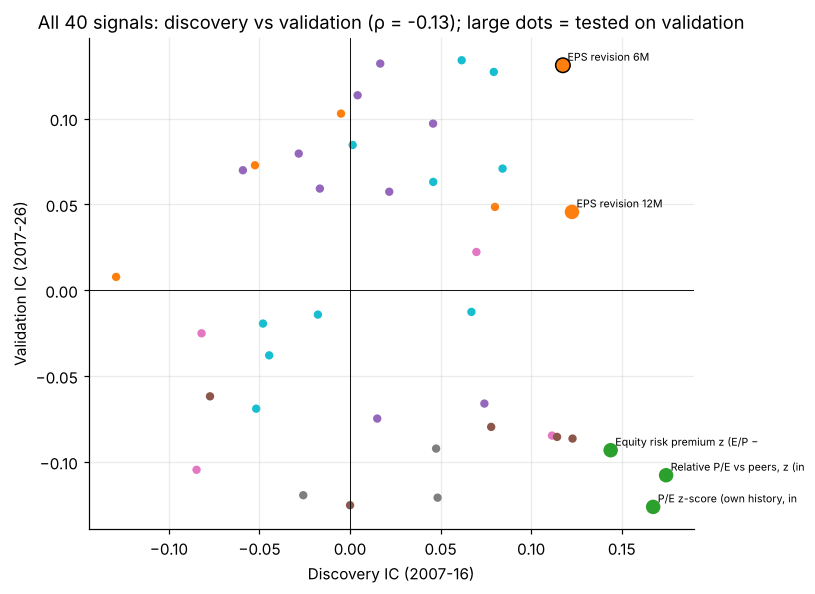

In [7]:
rho = spearmanr(res.disc_IC, res.val_IC)
rho_new = spearmanr(res[~res.seen_before].disc_IC, res[~res.seen_before].val_IC)
print(f'Spearman(discovery IC, validation IC) across all {N} signals: {rho.statistic:+.2f} (p={rho.pvalue:.2f});  semi-clean families only: {rho_new.statistic:+.2f} (p={rho_new.pvalue:.2f})')
print(f'Mean validation IC of the top-10 discovery signals: {res.sort_values("disc_z", ascending=False).head(10).val_IC.mean():+.3f}   vs library average {res.val_IC.mean():+.3f}')

fig, ax = plt.subplots(figsize=(7.5, 5.5))
colr = res.pillar.map({'Micro': '#ff7f0e', 'Valuation': '#2ca02c', 'Rates': '#8c564b', 'Credit': '#e377c2', 'FX': '#7f7f7f', 'Technical': '#9467bd', 'Macro': '#17becf'})
ax.scatter(res.disc_IC, res.val_IC, c=colr, s=np.where(res.tested_in_validation, 90, 30), edgecolor=np.where(res.validated, 'k', 'none'))
for n_, r_ in res[res.tested_in_validation].iterrows(): ax.annotate(n_[:28], (r_.disc_IC, r_.val_IC), fontsize=7, xytext=(3, 3), textcoords='offset points')
ax.axhline(0, color='k', lw=.6); ax.axvline(0, color='k', lw=.6); ax.set_xlabel('Discovery IC (2007-16)'); ax.set_ylabel('Validation IC (2017-26)')
ax.set_title(f'All {N} signals: discovery vs validation (ρ = {rho.statistic:+.2f}); large dots = tested on validation'); plt.tight_layout()
plt.savefig(CH/'fig_v3_discovery_vs_validation.png', dpi=200, bbox_inches='tight'); plt.show()

## 5b. Stage 2 — pooled full-sample test with the same max-statistic control
More months → more power. Same 40 signals, same fixed directions, same family-wise (Westfall-Young) adjustment, plus the requirement that the IC has the **same sign in both windows**.

In [8]:
M_FULL = np.array([p >= DISC[0] for p in IDX])
ic_f, t_f, n_f = window_stats(IC[key], M_FULL)
obs_f, z_f, praw_f, padj_f, maxnull_f = block_perm_null(S, FR[key], M_FULL, seed=SEED + 2)
res = res.join(pd.DataFrame({'full_months': n_f, 'full_IC': ic_f, 'full_NW_t': t_f, 'full_z': z_f, 'full_p_raw': praw_f, 'full_p_adj(WY)': padj_f}, index=NAMES))
res['both_windows_positive'] = (res.disc_IC > 0) & (res.val_IC > 0)
res['robust'] = (res['full_p_adj(WY)'] <= ADJ_P_CAND) & res.both_windows_positive
ROBUST = list(res.index[res.robust])
c2 = ['pillar', 'seen_before', 'full_IC', 'full_NW_t', 'full_p_raw', 'full_p_adj(WY)', 'disc_IC', 'val_IC', 'both_windows_positive', 'robust']
display(res.sort_values('full_z', ascending=False).head(12)[c2].style.format({'full_IC': '{:+.3f}', 'full_NW_t': '{:+.2f}', 'full_p_raw': '{:.3f}', 'full_p_adj(WY)': '{:.3f}', 'disc_IC': '{:+.3f}', 'val_IC': '{:+.3f}'}))
print(f'Full-sample: best z = {res.full_z.max():.2f}; best-of-{N} null 95th pct = {np.percentile(maxnull_f, 95):.2f}; signals with adj p <= {ADJ_P_CAND}: {int((res["full_p_adj(WY)"] <= ADJ_P_CAND).sum())}')
print('ROBUST set (adj p <= 0.10 AND positive in both windows):', ROBUST if ROBUST else 'NONE')
# family view of earnings revisions (all lookbacks, fixed hypotheses) — descriptive
fam = res[res.pillar == 'Micro'][['disc_IC', 'val_IC', 'full_IC', 'full_NW_t', 'full_p_adj(WY)']]
display(fam.style.format('{:+.3f}'))

,pillar,seen_before,full_IC,full_NW_t,full_p_raw,full_p_adj(WY),disc_IC,val_IC,both_windows_positive,robust
EPS revision 6M,Micro,False,+0.122,+2.38,0.003,0.094,+0.117,+0.131,True,True
FCI easing 6M,Macro,False,+0.101,+2.00,0.011,0.272,+0.079,+0.127,True,False
FCI easing 12M,Macro,False,+0.091,+1.73,0.032,0.561,+0.062,+0.134,True,False
EPS revision 12M,Micro,False,+0.085,+1.60,0.031,0.587,+0.122,+0.046,True,False
FCI easing 3M,Macro,True,+0.074,+1.62,0.033,0.660,+0.084,+0.071,True,False
EPS growth minus price growth 6M,Micro,False,+0.069,+1.59,0.048,0.762,+0.080,+0.049,True,False
Credit spread change 1M (tightening = good),Credit,False,+0.050,+1.46,0.085,0.890,+0.070,+0.022,True,False
Momentum 12-1M,Technical,True,+0.061,+1.35,0.081,0.899,+0.046,+0.097,True,False
Risk-adjusted momentum 12-1M,Technical,False,+0.057,+1.28,0.092,0.933,+0.017,+0.132,True,False
Momentum 9-1M,Technical,False,+0.054,+1.20,0.108,0.948,+0.004,+0.114,True,False


Full-sample: best z = 2.75; best-of-40 null 95th pct = 2.99; signals with adj p <= 0.1: 1
ROBUST set (adj p <= 0.10 AND positive in both windows): ['EPS revision 6M']


,disc_IC,val_IC,full_IC,full_NW_t,full_p_adj(WY)
EPS revision 6M,+0.117,+0.131,+0.122,+2.376,+0.094
EPS revision 12M,+0.122,+0.046,+0.085,+1.596,+0.587
EPS growth minus price growth 6M,+0.080,+0.049,+0.069,+1.586,+0.762
EPS revision 3M,-0.005,+0.103,+0.044,+0.951,+0.984
EPS revision 1M,-0.052,+0.073,+0.005,+0.140,+1.000
EPS acceleration (3M vs prior 3M),-0.129,+0.008,-0.067,-1.610,+1.000


### Pillar-best signals (mechanical rule, see protocol)

In [9]:
gate = res.both_windows_positive & (res.full_p_raw <= 0.05)
TIER_A = {}
for pil in res.pillar.unique():
    c_ = res[(res.pillar == pil) & gate]
    if len(c_): TIER_A[pil] = c_.full_z.idxmax()
FOUR = {}
for pil in ['Micro', 'Macro', 'Technical', 'Valuation']:
    c_ = res[(res.pillar == pil) & res.both_windows_positive]; fb = False
    if not len(c_): c_ = res[res.pillar == pil]; fb = True
    FOUR[pil] = (c_.full_z.idxmax(), fb)
tab = pd.DataFrame({'v3b Tier-A signal (weight > 0)': pd.Series(TIER_A), 'v3c signal': pd.Series({k_: v[0] for k_, v in FOUR.items()}),
                    'v3c fallback (no sign-stable signal)': pd.Series({k_: v[1] for k_, v in FOUR.items()})})
display(tab.fillna('— (zero weight)'))
for pil, (nm_, fb) in FOUR.items():
    r_ = res.loc[nm_]; print(f'  {pil:10s} {nm_:42s} full IC {r_.full_IC:+.3f} (raw p {r_.full_p_raw:.3f}, adj p {r_["full_p_adj(WY)"]:.2f}) | disc {r_.disc_IC:+.3f} | val {r_.val_IC:+.3f}' + ('   <-- fallback' if fb else ''))

,v3b Tier-A signal (weight > 0),v3c signal,v3c fallback (no sign-stable signal)
Macro,FCI easing 6M,FCI easing 6M,False
Micro,EPS revision 6M,EPS revision 6M,False
Technical,— (zero weight),Momentum 12-1M,False
Valuation,— (zero weight),"Relative P/E vs peers, z (inverted)",True


  Micro      EPS revision 6M                            full IC +0.122 (raw p 0.003, adj p 0.09) | disc +0.117 | val +0.131
  Macro      FCI easing 6M                              full IC +0.101 (raw p 0.011, adj p 0.27) | disc +0.079 | val +0.127
  Technical  Momentum 12-1M                             full IC +0.061 (raw p 0.081, adj p 0.90) | disc +0.046 | val +0.097
  Valuation  Relative P/E vs peers, z (inverted)        full IC +0.037 (raw p 0.215, adj p 1.00) | disc +0.174 | val -0.108   <-- fallback


## 6. Reference composites (same library, same windows) and the v3 composite

In [10]:
def cs_z(df):
    ok = df.notna().all(axis=1); return df.sub(df.mean(axis=1), axis=0).div(df.std(axis=1, ddof=1), axis=0).where(ok)

def make_composite(names):
    byp = {}
    for n in names: byp.setdefault(META[n]['pillar'], []).append(cs_z(LIB[n]))
    ps = [sum(v) / len(v) for v in byp.values()]
    return sum(ps) / len(ps)

REF = {'v1-like: PMI Δ3M + EPS 3M + P/E z + Mom 12-1': ['PMI change 3M (lag 1M)', 'EPS revision 3M', 'P/E z-score (own history, inverted)', 'Momentum 12-1M'],
       'v2-like (S1): FCI 3M + EPS 3M + P/E z + Mom 12-1': ['FCI easing 3M', 'EPS revision 3M', 'P/E z-score (own history, inverted)', 'Momentum 12-1M']}
COMPS = {k_: make_composite(v) for k_, v in REF.items()}
SETS = dict(REF)
if VALIDATED: SETS['v3a: Stage-1 validated'] = VALIDATED; COMPS['v3a: Stage-1 validated'] = make_composite(VALIDATED)
if TIER_A: SETS['v3b: Tier-A pillars (HEADLINE)'] = list(TIER_A.values()); COMPS['v3b: Tier-A pillars (HEADLINE)'] = make_composite(SETS['v3b: Tier-A pillars (HEADLINE)'])
SETS['v3c: 4 required pillars'] = [v[0] for v in FOUR.values()]; COMPS['v3c: 4 required pillars'] = make_composite(SETS['v3c: 4 required pillars'])
HEAD3 = 'v3b: Tier-A pillars (HEADLINE)' if TIER_A else 'v3a: Stage-1 validated'
print('Composite definitions:'); [print(' -', k_, '->', SETS[k_]) for k_ in COMPS]

def rank_ic_df(comp, f):
    s = comp.copy(); r = rank_array(s); Fr = rank_array(f); return pd.Series(ic_matrix(r[None], Fr)[0], index=comp.index)

rows = []
for name, comp in COMPS.items():
    for lab, mask in (('Discovery 2007-16', M_DISC), ('Validation 2017-26', M_VAL)):
        for kk in (('USD', 3), ('local', 3), ('USD', 6), ('local', 6)):
            ic = rank_ic_df(comp, fwd[kk]); x = ic[mask].dropna()
            rows.append({'Composite': name, 'Window': lab, 'Return': f'{kk[0]} {kk[1]}M', 'Mean IC': x.mean(), 'NW t': nw_t(x.to_numpy(), kk[1]), 'Hit-rate': (x > 0).mean(), 'N': len(x)})
COMP_IC = pd.DataFrame(rows)
display(COMP_IC.pivot_table(index=['Composite', 'Window'], columns='Return', values='Mean IC').style.format('{:+.3f}'))

Composite definitions:
 - v1-like: PMI Δ3M + EPS 3M + P/E z + Mom 12-1 -> ['PMI change 3M (lag 1M)', 'EPS revision 3M', 'P/E z-score (own history, inverted)', 'Momentum 12-1M']
 - v2-like (S1): FCI 3M + EPS 3M + P/E z + Mom 12-1 -> ['FCI easing 3M', 'EPS revision 3M', 'P/E z-score (own history, inverted)', 'Momentum 12-1M']
 - v3a: Stage-1 validated -> ['EPS revision 6M']
 - v3b: Tier-A pillars (HEADLINE) -> ['EPS revision 6M', 'FCI easing 6M']
 - v3c: 4 required pillars -> ['EPS revision 6M', 'FCI easing 6M', 'Momentum 12-1M', 'Relative P/E vs peers, z (inverted)']


## 7. Backtest of the composites (validation window = the only part not used to choose signals)
Mechanics identical to v1/v2: score-weighted dollar-neutral L/S, 3M tranches, gross of costs, positions earn t → t+1; long-only top-2 vs equal-weight benchmark. Permutation test = shuffle country labels of the composite in 3M blocks (3,000 draws, one-sided).

In [11]:
def base_w_ls(score): return score.div(score.clip(lower=0).sum(axis=1), axis=0)
def base_w_lo(score): return (score.rank(axis=1, ascending=False) <= 2).astype(float) / 2
def held(wb, H): return wb.rolling(H, min_periods=1).mean()
def port_ret(w, r):
    ww = w.shift(1).dropna(how='any'); return (ww * r.reindex(ww.index)).sum(axis=1, min_count=1)
def max_dd(r):
    c = (1 + r).cumprod(); return (c / c.cummax() - 1).min()
def stats_(r):
    n = len(r); ann = (1 + r).prod() ** (12 / n) - 1; vol = r.std() * np.sqrt(12)
    return {'Ann. return': ann, 'Ann. vol': vol, 'Sharpe': r.mean() * 12 / vol, 'Max drawdown': max_dd(r), 'Hit rate': (r > 0).mean()}

def sharpe_perm(comp, R, H=3, block=3, n_perm=P_PERM, seed=SEED):
    W = base_w_ls(comp).to_numpy(); Rm = R.reindex(comp.index).to_numpy(); T_ = W.shape[0]
    blk = np.arange(T_) // block; B = blk.max() + 1
    perms = np.argsort(np.random.default_rng(seed).random((n_perm, B, W.shape[1])), axis=2)[:, blk, :]
    def run(Wp):
        cs = np.cumsum(Wp, axis=1); lag = np.zeros_like(cs); lag[:, H:, :] = cs[:, :-H, :]
        hd = (cs - lag) / np.minimum(np.arange(T_) + 1, H)[None, :, None]; ret = (hd[:, :-1, :] * Rm[None, 1:, :]).sum(-1)
        return ret.mean(1) / ret.std(1, ddof=1) * np.sqrt(12)
    obs = run(W[None])[0]; null = run(np.take_along_axis(np.broadcast_to(W, (n_perm,) + W.shape), perms, axis=2))
    return obs, (np.sum(null >= obs) + 1) / (n_perm + 1)

EW = pd.DataFrame(0.2, index=IDX, columns=COUNTRIES)
BT, rows = {}, []
for name, comp in COMPS.items():
    for basis, R in (('USD', R_USD), ('local', R_LOC)):
        r_ls = port_ret(held(base_w_ls(comp), 3), R); r_lo = port_ret(held(base_w_lo(comp), 3), R); r_bm = port_ret(EW, R)
        BT[(name, basis)] = pd.DataFrame({'LS': r_ls, 'LongOnly_top2': r_lo, 'EW': r_bm})
        for lab, lo_ in (('Discovery 2007-16', DISC[0]), ('Validation 2017-26', VAL_START + 1)):
            hi_ = DISC[1] + 1 if lab.startswith('Disc') else AS_OF
            a = r_ls[(r_ls.index >= lo_) & (r_ls.index <= hi_)].dropna(); b = (r_lo - r_bm)[(r_lo.index >= lo_) & (r_lo.index <= hi_)].dropna()
            cw = comp.loc[lo_ - 1:hi_] if lab.startswith('Valid') else comp.loc[DISC[0]:DISC[1]]
            sh, p = sharpe_perm(cw.dropna(how='any'), R) if basis == 'USD' else (np.nan, np.nan)
            rows.append({'Composite': name, 'Basis': basis, 'Window': lab, 'L/S Sharpe': stats_(a)['Sharpe'], 'L/S ann. ret': stats_(a)['Ann. return'], 'L/S max DD': stats_(a)['Max drawdown'],
                         'Active IR (top2−EW)': b.mean() * 12 / (b.std() * np.sqrt(12)), 'Perm p (Sharpe, 1-sided)': p, 'months': len(a)})
BTS = pd.DataFrame(rows)
display(BTS.set_index(['Composite', 'Window', 'Basis']).style.format({'L/S Sharpe': '{:.2f}', 'L/S ann. ret': '{:.1%}', 'L/S max DD': '{:.1%}', 'Active IR (top2−EW)': '{:.2f}', 'Perm p (Sharpe, 1-sided)': '{:.3f}'}, na_rep='–'))

## 8. Robustness of whatever survives (only if a v3 composite exists)

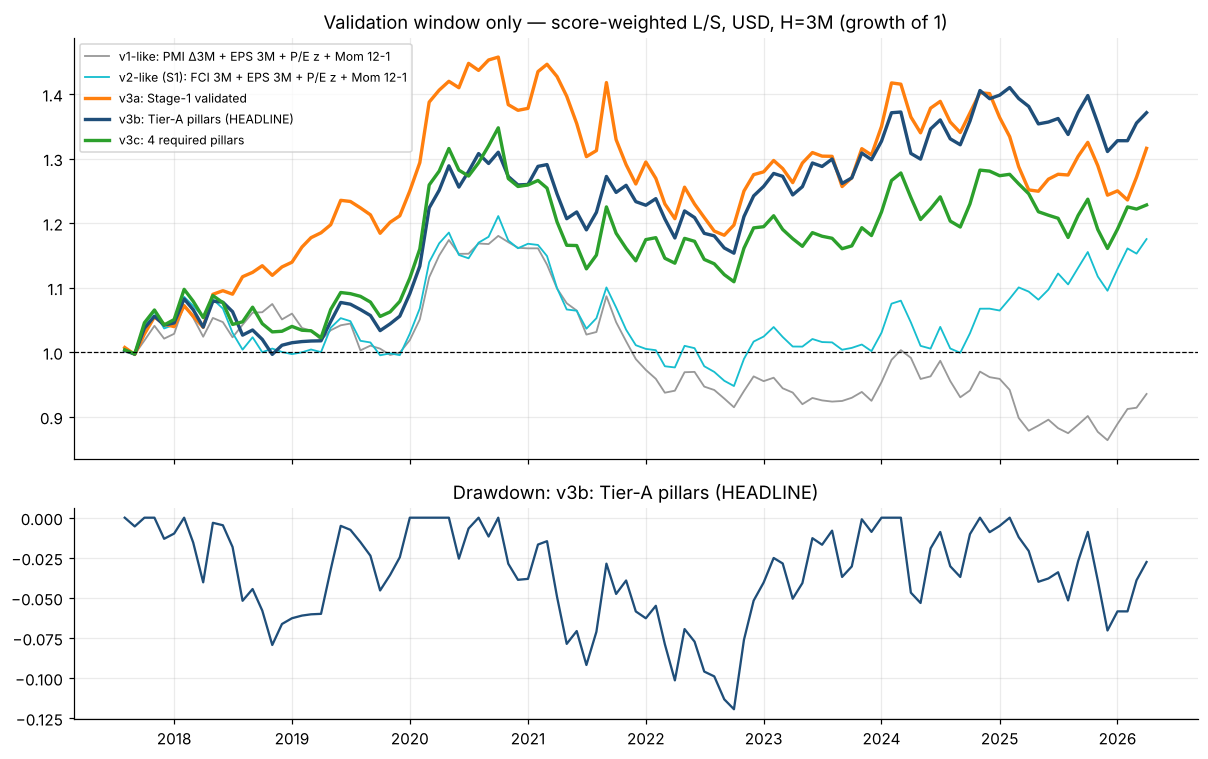

Leave-one-market-out — v3a: Stage-1 validated


,Sharpe (validation),Ann. return
Dropped market,,
US,0.18,1.3%
Eurozone,0.52,4.4%
UK,0.32,2.6%
Switzerland,0.28,2.1%
Japan,0.54,4.6%


Leave-one-market-out — v3b: Tier-A pillars (HEADLINE)


,Sharpe (validation),Ann. return
Dropped market,,
US,0.13,0.8%
Eurozone,0.54,4.3%
UK,0.55,4.3%
Switzerland,0.34,2.6%
Japan,0.73,5.8%


Leave-one-market-out — v3c: 4 required pillars


,Sharpe (validation),Ann. return
Dropped market,,
US,0.03,-0.1%
Eurozone,0.41,3.2%
UK,0.20,1.4%
Switzerland,0.11,0.6%
Japan,0.57,4.6%


In [12]:
V3S = [k_ for k_ in COMPS if k_.startswith('v3')]
if V3S:
    fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
    cmap_ = {'v1-like': '#999999', 'v2-like': '#17becf', 'v3a': '#ff7f0e', 'v3b': '#1f4e79', 'v3c': '#2ca02c'}
    for nm in COMPS:
        r = BT[(nm, 'USD')]['LS']; r = r[r.index >= VAL_START + 1].dropna(); cum = (1 + r).cumprod(); c_ = cmap_[nm.split(':')[0].split(' ')[0]]
        ax[0].plot(cum.index.to_timestamp(), cum, color=c_, lw=2.2 if nm.startswith('v3') else 1.2, label=nm[:50])
        if nm == HEAD3: ax[1].plot(cum.index.to_timestamp(), cum / cum.cummax() - 1, color=c_)
    ax[0].axhline(1, color='k', ls='--', lw=.8); ax[0].set_title('Validation window only — score-weighted L/S, USD, H=3M (growth of 1)'); ax[0].legend(fontsize=8); ax[1].set_title(f'Drawdown: {HEAD3}')
    plt.tight_layout(); plt.savefig(CH/'fig_v3_backtest_validation.png', dpi=200, bbox_inches='tight'); plt.show()
    for nm in V3S:
        sig_set = SETS[nm]; lo_rows = []
        for drop in COUNTRIES:
            keep = [c for c in COUNTRIES if c != drop]
            ck = sum(cs_z(LIB[n][keep]) for n in sig_set) / len(sig_set)
            rr = port_ret(held(base_w_ls(ck), 3), R_USD[keep]); rr = rr[rr.index >= VAL_START + 1].dropna()
            lo_rows.append({'Dropped market': drop, 'Sharpe (validation)': rr.mean() * 12 / (rr.std() * np.sqrt(12)), 'Ann. return': (1 + rr).prod() ** (12 / len(rr)) - 1})
        print('Leave-one-market-out —', nm); display(pd.DataFrame(lo_rows).set_index('Dropped market').style.format({'Sharpe (validation)': '{:.2f}', 'Ann. return': '{:.1%}'}))
else:
    print('No signal validated -> no v3 composite is built (the rule is not relaxed).')

## 9. Integrity checks

In [13]:
# (1) vectorised IC == scipy for random signals/months
rng = np.random.default_rng(1)
for _ in range(6):
    i = int(rng.integers(N)); t = int(rng.integers(20, len(IDX) - 4))
    if np.isnan(IC[key][i, t]): continue
    assert abs(spearmanr(LIB[NAMES[i]].iloc[t], fwd[key].iloc[t]).statistic - IC[key][i, t]) < 1e-9
# (2) permutation engine reproduces the plain mean IC (asserted in section 4)
# (3) look-ahead: signals rebuilt from data truncated at T must equal the full-sample values at T
def build_library(PE, EPS, PMI, Y2, OAS, FCI, FX, IDX):
    PX = PE * EPS; R_LOC = PX.pct_change(); L = {}
    PM_ = PMI.shift(1)
    L['EPS revision 3M'] = pct(EPS, 3); L['P/E z-score (own history, inverted)'] = -zexp(PE); L['Momentum 12-1M'] = PX.shift(1) / PX.shift(12) - 1
    L['2Y yield change 3M (falling = good)'] = -own(chg(Y2, 3)); L['Credit spread level z (wide = good)'] = zexp(OAS); L['FCI easing 3M'] = own(chg(FCI, 3))
    L['PMI change 3M (lag 1M)'] = chg(PM_, 3); L['Low realised vol (12M, inverted)'] = -R_LOC.rolling(12).std()
    L['FX appreciation momentum 6M'] = pct(FX, 6); L['Distance to 12M high'] = PX / PX.rolling(12).max() - 1
    return L
for T in (pd.Period('2013-06', 'M'), pd.Period('2021-03', 'M')):
    Lt = build_library(*(x.loc[:T] for x in (PE, EPS, PMI, Y2, OAS, FCI, FX)), IDX[IDX <= T])
    for n_, df_ in Lt.items():
        a, b = df_.loc[T].to_numpy(float), LIB[n_].loc[T].to_numpy(float)
        assert np.allclose(a, b, equal_nan=True), (n_, T)
print('Look-ahead test passed for 10 representative signals at 2 dates (signals computed from truncated data equal the full-sample values).')

Look-ahead test passed for 10 representative signals at 2 dates (signals computed from truncated data equal the full-sample values).


## 9b. Current ranking (headline v3b) and stability across every specification

,Macro,Micro,Valuation,Technical,v3 score,v3 rank,v3 stance,v3 call,rank_v1-like,rank_v2-like (S1),rank_v3a,rank_v3b,rank_v3c
US,1.091,1.265,-1.509,0.049,1.178,1,Overweight,Overweight,3,3,1,1,2
Japan,-0.196,0.152,0.199,1.452,-0.022,2,Overweight,Neutral,2,1,3,2,1
Eurozone,0.317,-0.389,-0.071,-0.707,-0.036,3,Neutral,Neutral,5,5,4,3,4
Switzerland,0.378,-1.435,0.087,-1.130,-0.529,4,Underweight,Underweight,4,4,5,4,5
UK,-1.590,0.407,1.293,0.336,-0.592,5,Underweight,Underweight,1,2,2,5,3


Pillar weights in v3 headline: {'Macro': '50%', 'Micro': '50%', 'Valuation': '0%', 'Technical': '0%'} | signals shown for zero-weight pillars: Valuation: Relative P/E vs peers, z (inverted), Technical: Momentum 12-1M


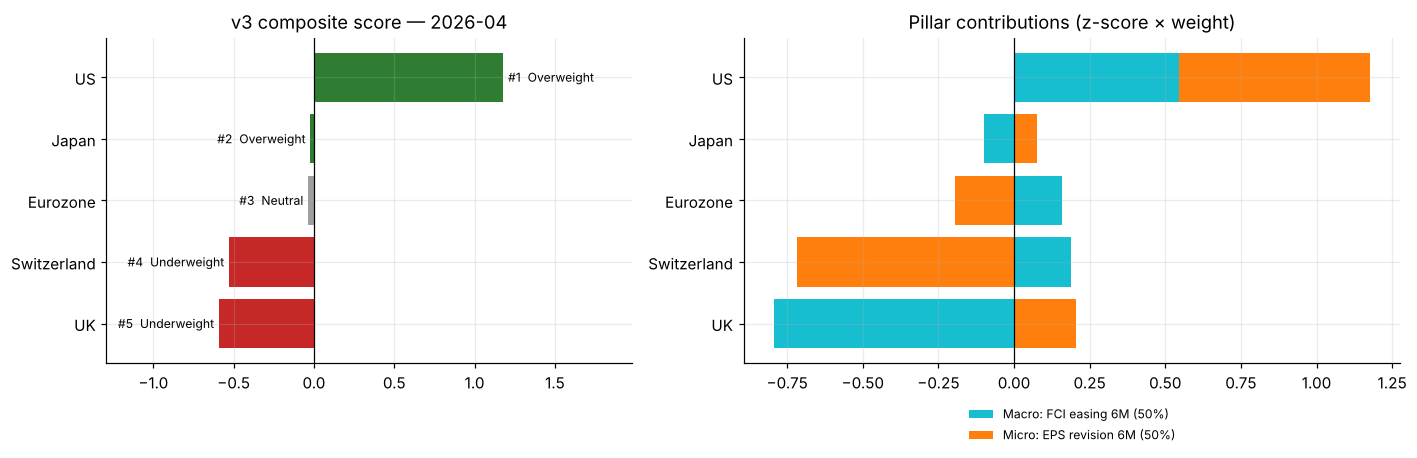

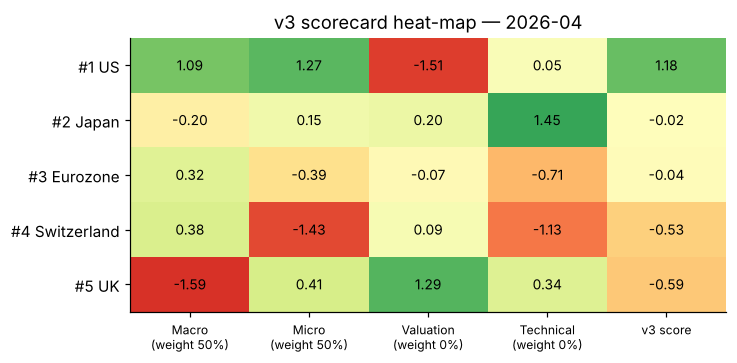

In [14]:
STANCE = {1: 'Overweight', 2: 'Overweight', 3: 'Neutral', 4: 'Underweight', 5: 'Underweight'}
pill_sig = {p_: FOUR[p_][0] for p_ in ['Macro', 'Micro', 'Valuation', 'Technical']}
Zc = pd.DataFrame({p_: cs_z(LIB[n_]).loc[AS_OF] for p_, n_ in pill_sig.items()})
W_P = {p_: (1 / len(TIER_A) if p_ in TIER_A else 0.0) for p_ in Zc.columns}
score_b = sum(cs_z(LIB[n_]).loc[AS_OF] for n_ in SETS[HEAD3]) / len(SETS[HEAD3])
assert np.allclose(score_b.values, COMPS[HEAD3].loc[AS_OF].values)
cur = Zc.copy(); cur['v3 score'] = score_b; cur['v3 rank'] = cur['v3 score'].rank(ascending=False).astype(int); cur['v3 stance'] = cur['v3 rank'].map(STANCE)
cur['v3 call'] = np.where(cur['v3 score'] >= 0.1, 'Overweight', np.where(cur['v3 score'] <= -0.1, 'Underweight', 'Neutral'))   # recommendation rule: |score| < 0.1 = no real view (tie), otherwise sign of the score
ranks_all = pd.DataFrame({k_: COMPS[k_].loc[AS_OF].rank(ascending=False).astype(int) for k_ in COMPS}); ranks_all.columns = [c_.split(':')[0] for c_ in ranks_all.columns]
cur = cur.join(ranks_all.add_prefix('rank_')).sort_values('v3 rank'); display(cur)
print('Pillar weights in v3 headline:', {k_: f'{v_:.0%}' for k_, v_ in W_P.items()}, '| signals shown for zero-weight pillars: ' + ', '.join(f'{p_}: {n_}' for p_, n_ in pill_sig.items() if W_P[p_] == 0))

PC = {'Macro': '#17becf', 'Micro': '#ff7f0e', 'Valuation': '#2ca02c', 'Technical': '#9467bd'}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={'width_ratios': [1, 1.25]})
c2 = cur.sort_values('v3 score')
ax[0].barh(c2.index, c2['v3 score'], color=['#2e7d32' if x_ == 'Overweight' else '#c62828' if x_ == 'Underweight' else '#9e9e9e' for x_ in c2['v3 stance']])
for i_, (idx_, rw) in enumerate(c2.iterrows()):
    ax[0].text(rw['v3 score'] + (0.03 if rw['v3 score'] >= 0 else -0.03), i_, f"#{rw['v3 rank']}  {rw['v3 stance']}", va='center', ha='left' if rw['v3 score'] >= 0 else 'right', fontsize=8)
ax[0].axvline(0, color='k', lw=.8); ax[0].set_title(f'v3 composite score — {AS_OF}'); ax[0].set_xlim(c2['v3 score'].min() - .7, c2['v3 score'].max() + .8)
pos_ = np.zeros(len(c2)); neg_ = np.zeros(len(c2))
for p_ in ['Macro', 'Micro', 'Valuation', 'Technical']:
    if W_P[p_] == 0: continue
    v_ = (c2[p_] * W_P[p_]).values; b_ = np.where(v_ >= 0, pos_, neg_)
    ax[1].barh(c2.index, v_, left=b_, color=PC[p_], label=f'{p_}: {pill_sig[p_]} ({W_P[p_]:.0%})'); pos_ = pos_ + np.where(v_ >= 0, v_, 0); neg_ = neg_ + np.where(v_ < 0, v_, 0)
ax[1].axvline(0, color='k', lw=.8); ax[1].set_title('Pillar contributions (z-score × weight)'); ax[1].legend(fontsize=8, ncol=1, loc='upper center', bbox_to_anchor=(0.5, -0.1), frameon=False)
plt.tight_layout(); plt.savefig(CH/'fig_v3_current_ranking.png', dpi=200, bbox_inches='tight'); plt.show()

fig, a = plt.subplots(figsize=(6.8, 3.4)); hm = cur[['Macro', 'Micro', 'Valuation', 'Technical', 'v3 score']]
a.imshow(hm.values, cmap='RdYlGn', vmin=-2, vmax=2, aspect='auto'); a.set_xticks(range(5)); a.set_xticklabels([f'{c_}\n(weight {W_P[c_]:.0%})' if c_ in W_P else c_ for c_ in hm.columns], fontsize=8)
a.set_yticks(range(len(hm))); a.set_yticklabels([f'#{r_} {i_}' for i_, r_ in zip(hm.index, cur['v3 rank'])])
for i_ in range(hm.shape[0]):
    for j_ in range(hm.shape[1]): a.text(j_, i_, f'{hm.values[i_, j_]:.2f}', ha='center', va='center', fontsize=9)
a.grid(False); a.set_title(f'v3 scorecard heat-map — {AS_OF}'); plt.tight_layout(); plt.savefig(CH/'fig_v3_scorecard_heatmap.png', dpi=200, bbox_inches='tight'); plt.show()
cur.reset_index(names='country').to_csv(OUT/'current_ranking_v3.csv', index=False)

## 10. Results summary

In [15]:
top5 = res.sort_values('disc_z', ascending=False).head(5)
md = f"""
**Search:** {N} signals × discovery window {DISC[0]}→{DISC[1]}. Best discovery z = **{disc.disc_z.max():.2f}**; best-of-{N} noise 95th percentile = **{np.percentile(maxnull_d, 95):.2f}**.
Signals passing the family-wise rule (adj. p ≤ {ADJ_P_CAND}): **{int((disc['disc_p_adj(WY)'] <= ADJ_P_CAND).sum())}**; unadjusted p ≤ 0.05: {int((disc.disc_p_raw <= 0.05).sum())} (chance alone gives ≈ {0.05 * N:.0f}).

**Validation (frozen, {VAL_START}→{AS_OF}):** tested {k} signals; **validated: {', '.join(VALIDATED) if VALIDATED else 'none'}**.
Across the library, discovery IC vs validation IC: ρ = {rho.statistic:+.2f} (semi-clean families: {rho_new.statistic:+.2f}).

**Stage 2 (pooled, no hold-out):** best full-sample z = {res.full_z.max():.2f} vs best-of-{N} null 95th pct {np.percentile(maxnull_f, 95):.2f}; signals with adj. p ≤ {ADJ_P_CAND}: {int((res['full_p_adj(WY)'] <= ADJ_P_CAND).sum())};
**robust set: {', '.join(ROBUST) if ROBUST else 'none'}**.

**Pillar scorecards:** v3b (headline) uses {', '.join(SETS.get('v3b: Tier-A pillars (HEADLINE)', []))}; v3c uses {', '.join(SETS['v3c: 4 required pillars'])}.
"""
display(Markdown(md))


**Search:** 40 signals × discovery window 2007-01→2016-12. Best discovery z = **2.64**; best-of-40 noise 95th percentile = **2.95**.
Signals passing the family-wise rule (adj. p ≤ 0.1): **0**; unadjusted p ≤ 0.05: 8 (chance alone gives ≈ 2).

**Validation (frozen, 2017-07→2026-04):** tested 5 signals; **validated: EPS revision 6M**.
Across the library, discovery IC vs validation IC: ρ = -0.13 (semi-clean families: -0.10).

**Stage 2 (pooled, no hold-out):** best full-sample z = 2.75 vs best-of-40 null 95th pct 2.99; signals with adj. p ≤ 0.1: 1;
**robust set: EPS revision 6M**.

**Pillar scorecards:** v3b (headline) uses EPS revision 6M, FCI easing 6M; v3c uses EPS revision 6M, FCI easing 6M, Momentum 12-1M, Relative P/E vs peers, z (inverted).


## 11. Export

In [16]:
res.reset_index(names='signal').to_csv(OUT/'signal_library_discovery_validation.csv', index=False)
pd.DataFrame({'null_max_z_full': maxnull_f}).to_csv(OUT/'full_sample_null_max_z.csv', index=False)
pd.DataFrame({'null_max_z': maxnull_d}).to_csv(OUT/'discovery_null_max_z.csv', index=False)
COMP_IC.to_csv(OUT/'composite_ic.csv', index=False); BTS.to_csv(OUT/'backtest_stats_v3.csv', index=False)
lib_long = pd.concat({n: LIB[n] for n in NAMES}, names=['signal', 'month']).stack().rename('value').reset_index().rename(columns={'level_2': 'country'})
lib_long['month'] = lib_long['month'].dt.to_timestamp('M'); lib_long.to_csv(OUT/'signal_values_monthly.csv', index=False)
cur = pd.DataFrame({k_: v.loc[AS_OF] for k_, v in COMPS.items()}); cur.to_csv(OUT/'current_scores_all_composites.csv')
print('Saved:', *[p.name for p in sorted(OUT.glob('*.csv'))], sep='\n  ')

Saved:
  backtest_stats_v3.csv
  composite_ic.csv
  current_ranking_v3.csv
  current_scores_all_composites.csv
  discovery_null_max_z.csv
  full_sample_null_max_z.csv
  signal_library_discovery_validation.csv
  signal_values_monthly.csv
